# Hacking the Gantt


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import datetime


In [8]:
gantt = pd.DataFrame([
    dict(Task="Retrieve family \nasteroid data", Start=0, Duration=4),
    dict(Task="Write Literature Review", Start=2, Duration=5),
    dict(Task="Generate the orbital data from the \nNASA Horizons system",
         Start=3, Duration=2),
    dict(Task="Create test-particle cloud", Start=4, Duration=3),
    dict(Task="Determine REBOUND config", Start=3, Duration=10),
    dict(Task="Create HPC jobs and software \nto log data", Start=6, Duration=10),
    dict(Task="Write Project Proposal", Start=8, Duration=5),
    dict(Task="Create scripts to analyse logs \nand extract summary information", Start=8, Duration=12),
    dict(Task="Create Proposal Presentation", Start=11, Duration=3),
    dict(Task="Analyse the logged data", Start=15, Duration=15),
    dict(Task="Write dissertation/ \npresent results", Start=18, Duration=15),
    dict(Task="Create final presentation", Start=30, Duration=4)
    ])

gantt['start_to_end'] = gantt.Start + gantt.Duration


In [15]:
gantt.sort_values('Start')

,Task,Start,Duration,start_to_end
0,Retrieve family \nasteroid data,0,4,4
1,Write Literature Review,2,5,7
2,Generate the orbital data from the \nNASA Hori...,3,2,5
4,Determine REBOUND config,3,10,13
3,Create test-particle cloud,4,3,7
5,Create HPC jobs and software \nto log data,6,10,16
6,Write Project Proposal,8,5,13
7,Create scripts to analyse logs \nand extract s...,8,12,20
8,Create Proposal Presentation,11,3,14
9,Analyse the logged data,15,15,30


In [31]:
start_date = datetime.datetime.strptime('2023-02-20', "%Y-%m-%d")
week_dates = [datetime.datetime.strftime(start_date+datetime.timedelta(weeks=week), '%m-%d') for week in range(0, 36, 4)]
gantt['start_to_end'] = gantt.Start + gantt.Duration


for task in gantt.sort_values('Start').index:
    print(gantt.loc[task]['Task'], ' & ', gantt.loc[task]['Start'], ' & ', gantt.loc[task]['Duration'],' \\\\ ',)

Retrieve family 
asteroid data  &  0  &  4  \\ 
Write Literature Review  &  2  &  5  \\ 
Generate the orbital data from the 
NASA Horizons system  &  3  &  2  \\ 
Determine REBOUND config  &  3  &  10  \\ 
Create test-particle cloud  &  4  &  3  \\ 
Create HPC jobs and software 
to log data  &  6  &  10  \\ 
Write Project Proposal  &  8  &  5  \\ 
Create scripts to analyse logs 
and extract summary information  &  8  &  12  \\ 
Create Proposal Presentation  &  11  &  3  \\ 
Analyse the logged data  &  15  &  15  \\ 
Write dissertation/ 
present results  &  18  &  15  \\ 
Create final presentation  &  30  &  4  \\ 


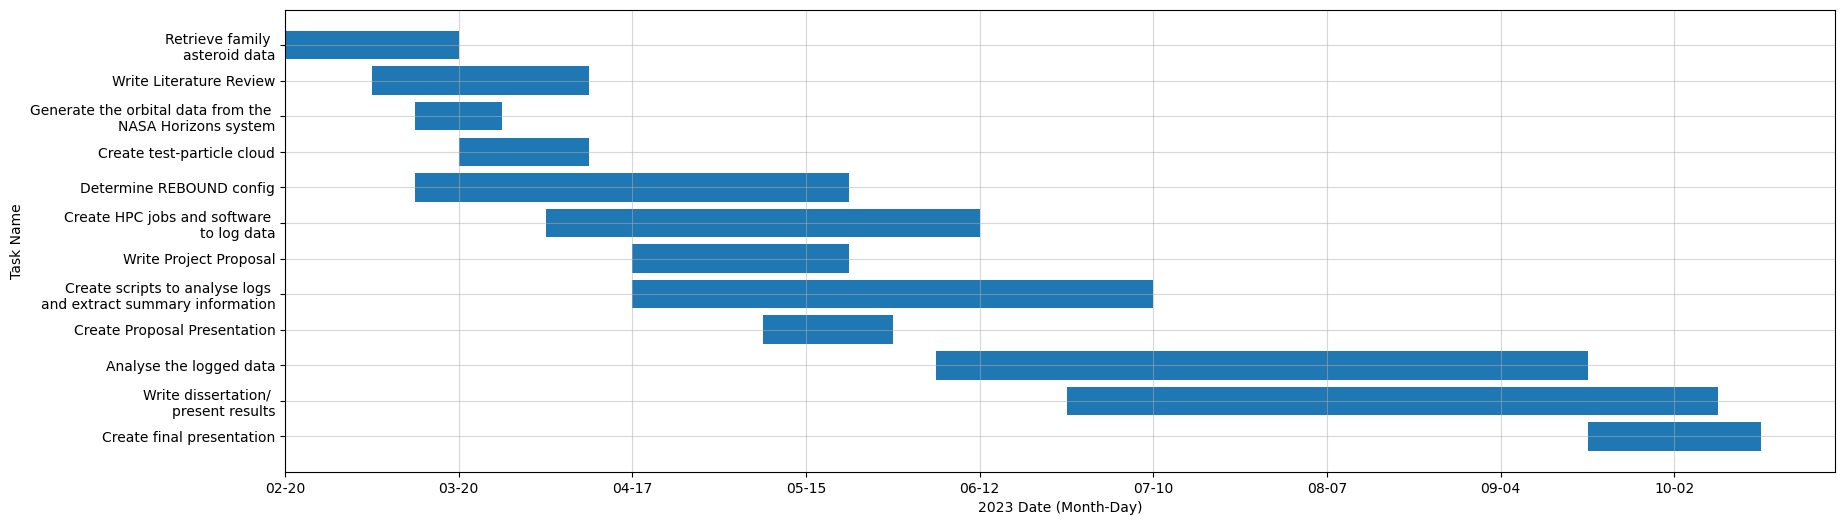

In [32]:

fig, ax = plt.subplots(1, figsize=(20, 6))
ax.barh(gantt.Task, gantt.Duration, left=gantt.Start)
ax.invert_yaxis()
ax.set_xlabel('2023 Date (Month-Day)')
ax.set_ylabel('Task Name')
ax.set_xticks(range(0, 36, 4), week_dates)
ax.grid(visible=True, axis='both', alpha=0.5)
plt.show()
